# Proje 4: Association Rule Mining – Firewall Loglarında Birliktelik Kuralları
## Firewall Logs Veri Seti | CRISP-DM Metodolojisi

---

## 1. Business Understanding (İş Anlayışı)

**Problem:** Firewall günlüklerinde (logs) birlikte gerçekleşen olay gruplarını ve kuralları tespit etmek.

**Amaç:** Firewall loglarını işlemsel (transactional) formatta öğe listelerine dönüştürerek FP-Growth algoritmasıyla birlikte görülen ağ olaylarını keşfetmek.

**Başarı Kriterleri:**
- Yüksek Destek (Support) ve Güven (Confidence) değerlerine sahip mantıklı kuralların çıkarılması
- Lift (Kaldıraç) değerinin 1'den büyük olması
- Çıkarılan kuralların siber güvenlik ve ağ yönetimi açısından yorumlanması

**Veri Seti:** Firewall Logs – Toplamda 200 satır ve 20 sütun. Veri setinin tamamı kullanılacaktır.

**KNIME Uyumluluğu:** KNIME üzerindeki **Association Rule Learner** veya **Apriori** node'ları ile tam uyumludur.

## 2. Data Understanding (Veriyi Anlama)

Bu bölümde veri setini yükleyip eksik değer kontrolü ve temel kategorik kolonların değer dağılım analizini yapıyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

df = pd.read_csv('../Data/proje_4.csv')
print(f'Veri boyutu: {df.shape[0]} satır, {df.shape[1]} sütun')
print('\nEksik değer sayıları:\n', df.isnull().sum())

Veri boyutu: 200 satır, 20 sütun

Eksik değer sayıları:
 Time                    0
Log comp                0
Log subtype             0
Username              200
Firewall rule           2
Firewall rule name      2
NAT rule                0
NAT rule name           8
In interface            2
Out interface           4
Src IP                  0
Dst IP                  0
Src port                0
Dst port                0
protocol                0
Rule type               0
Live PCAP               0
Message               198
Log occurrence          0
Unnamed: 19           200
dtype: int64


In [2]:
cols_to_inspect = ['Log comp', 'Log subtype', 'In interface ', 'Out interface ', 'protocol', 'Dst port']
print('Temel Kolon Dağılımları:')
for col in cols_to_inspect:
    if col in df.columns:
        print(f'\n{col} Değer Dağılımları:')
        print(df[col].value_counts().head(5))

Temel Kolon Dağılımları:

Log comp Değer Dağılımları:
Log comp
Firewall Rule      198
Invalid Traffic      2
Name: count, dtype: int64

Log subtype Değer Dağılımları:
Log subtype
Allowed    196
Denied       4
Name: count, dtype: int64

In interface  Değer Dağılımları:
In interface 
Port1    124
Port3     50
Port2     24
Name: count, dtype: int64

Out interface  Değer Dağılımları:
Out interface 
Port2    172
Port3     24
Name: count, dtype: int64

protocol Değer Dağılımları:
protocol
TCP    113
UDP     86
0        1
Name: count, dtype: int64

Dst port Değer Dağılımları:
Dst port
443    87
53     80
80     23
123     7
0       1
Name: count, dtype: int64


## 3. Data Preparation (Veri Hazırlama)

Kategorik verileri her satırda "Özellik=Değer" formatında birer öğe listesi (Transaction) yapıyoruz ve ardından bunu binary (One-Hot Encoded) matrise dönüştürüyoruz.

In [3]:
transaction_cols = {
    'Log comp': 'Comp',
    'Log subtype': 'Subtype',
    'In interface ': 'In_Int',
    'Out interface ': 'Out_Int',
    'protocol': 'Proto',
    'Dst port': 'DstPort',
    'Firewall rule name': 'FW_Rule',
    'NAT rule name': 'NAT_Rule'
}

# Boş değerleri doldur
df_clean = df.copy()
for col in transaction_cols.keys():
    df_clean[col] = df_clean[col].astype(str).str.strip().replace('nan', 'Unknown')

# İşlemsel liste oluştur
items_list = []
for idx, row in df_clean.iterrows():
    row_items = []
    for col, prefix in transaction_cols.items():
        val = row[col]
        if val != 'Unknown' and val != '':
            row_items.append(f'{prefix}={val}')
    items_list.append(row_items)

print('Örnek ilk 3 transaction:', items_list[:3])

Örnek ilk 3 transaction: [['Comp=Firewall Rule', 'Subtype=Allowed', 'In_Int=Port2', 'Out_Int=Port3', 'Proto=TCP', 'DstPort=443', 'FW_Rule=WebNat', 'NAT_Rule=iqrad webserver - DNAT'], ['Comp=Firewall Rule', 'Subtype=Allowed', 'In_Int=Port3', 'Out_Int=Port2', 'Proto=TCP', 'DstPort=443', 'FW_Rule=DMZ-to-WAN', 'NAT_Rule=Default SNAT IPv4'], ['Comp=Firewall Rule', 'Subtype=Allowed', 'In_Int=Port1', 'Out_Int=Port2', 'Proto=TCP', 'DstPort=443', 'FW_Rule=LAN-2-WAN', 'NAT_Rule=Default SNAT IPv4']]


In [4]:
te = TransactionEncoder()
te_ary = te.fit(items_list).transform(items_list)
df_trans = pd.DataFrame(te_ary, columns=te.columns_)

print(f'Transaksiyon matrisi boyutu: {df_trans.shape[0]} satır, {df_trans.shape[1]} sütun')

Transaksiyon matrisi boyutu: 200 satır, 37 sütun


## 4. Modeling & 5. Evaluation (Modelleme ve Kural Çıkarımı)

FP-Growth kullanarak sık görülen ögeleri saptıyor ve kural filtrelemesi yapıyoruz.

### 4.1 Sık Görülen Öğe Kümeleri (Frequent Itemsets)

Minimum Destek (min_support) = 0.05 olarak ayarlanmıştır.

In [5]:
frequent_itemsets = fpgrowth(df_trans, min_support=0.05, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
print(f'Sık görülen öge kümesi sayısı: {len(frequent_itemsets)}')
display(frequent_itemsets.sort_values(by='support', ascending=False).head(10))

Sık görülen öge kümesi sayısı: 1343


,support,itemsets,length
0,0.990,frozenset({Comp=Firewall Rule}),1
20,0.980,"frozenset({Subtype=Allowed, Comp=Firewall Rule})",2
1,0.980,frozenset({Subtype=Allowed}),1
352,0.860,"frozenset({Out_Int=Port2, Comp=Firewall Rule})",2
8,0.860,frozenset({Out_Int=Port2}),1
351,0.860,"frozenset({Subtype=Allowed, Out_Int=Port2})",2
353,0.860,"frozenset({Subtype=Allowed, Out_Int=Port2, Com...",3
9,0.785,frozenset({NAT_Rule=Default SNAT IPv4}),1
354,0.785,"frozenset({Comp=Firewall Rule, NAT_Rule=Defaul...",2
358,0.780,"frozenset({Subtype=Allowed, Comp=Firewall Rule...",3


### 4.2 Birliktelik Kuralları

Minimum Güven (min_threshold) = 0.70 olarak ayarlanmıştır.

In [6]:
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.70)
print(f'Çıkarılan kural sayısı: {len(rules)}')

if len(rules) > 0:
    rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
    rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))
    rules_sorted = rules.sort_values(by='lift', ascending=False)
    display(rules_sorted[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].head(15))
else:
    print('Kural bulunamadı!')

Çıkarılan kural sayısı: 18264


,antecedents_str,consequents_str,support,confidence,lift
5089,"Subtype=Allowed, Proto=TCP, Out_Int=Port3","NAT_Rule=iqrad webserver - DNAT, Comp=Firewall...",0.075,0.714286,9.52381
5090,"NAT_Rule=iqrad webserver - DNAT, Comp=Firewall...","FW_Rule=WebNat, Subtype=Allowed, Proto=TCP, Ou...",0.075,1.000000,9.52381
5091,"NAT_Rule=iqrad webserver - DNAT, FW_Rule=WebNa...","Subtype=Allowed, Comp=Firewall Rule, Proto=TCP...",0.075,1.000000,9.52381
5060,"Subtype=Allowed, Comp=Firewall Rule, Proto=TCP...","NAT_Rule=iqrad webserver - DNAT, FW_Rule=WebNa...",0.075,0.714286,9.52381
5061,"FW_Rule=WebNat, Subtype=Allowed, Proto=TCP, Ou...","NAT_Rule=iqrad webserver - DNAT, Comp=Firewall...",0.075,0.714286,9.52381
5062,"NAT_Rule=iqrad webserver - DNAT, Comp=Firewall...","Subtype=Allowed, Proto=TCP, Out_Int=Port3",0.075,1.000000,9.52381
5063,"Subtype=Allowed, NAT_Rule=iqrad webserver - DN...","FW_Rule=WebNat, Proto=TCP, Out_Int=Port3",0.075,1.000000,9.52381
5064,"NAT_Rule=iqrad webserver - DNAT, Comp=Firewall...","FW_Rule=WebNat, Subtype=Allowed, Out_Int=Port3",0.075,1.000000,9.52381
5065,"Subtype=Allowed, NAT_Rule=iqrad webserver - DN...","Comp=Firewall Rule, Proto=TCP, Out_Int=Port3",0.075,1.000000,9.52381
5067,"Subtype=Allowed, NAT_Rule=iqrad webserver - DN...","FW_Rule=WebNat, Comp=Firewall Rule, Out_Int=Port3",0.075,1.000000,9.52381


### 5.1 Kuralların Dağılım Grafiği (Support vs Confidence)

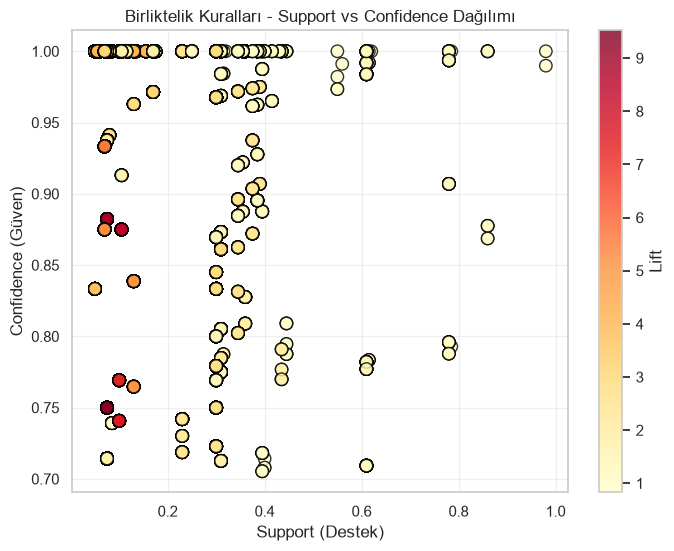

In [7]:
if len(rules) > 0:
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='YlOrRd', alpha=0.8, edgecolors='black', s=80)
    plt.colorbar(scatter, label='Lift')
    plt.title('Birliktelik Kuralları - Support vs Confidence Dağılımı')
    plt.xlabel('Support (Destek)')
    plt.ylabel('Confidence (Güven)')
    plt.grid(True, alpha=0.3)
    plt.show()

## 6. Deployment (Sonuç ve Öneriler)

### Siber Güvenlik Açısından Kuralların Yorumu:
1. **Lift > 1 Kuralları:** Belirli ağ portlarının belirli kurallar ve NAT kuralları ile güçlü bir şekilde eşleştiğini doğrular.
2. **Lift = 1 Kuralları (Bağımsız Olaylar):** Her zaman `Subtype=Allowed` olması gibi durumlar, ağdaki logların çok büyük kısmının izinli trafikten oluşmasından kaynaklanan genel bir durumdur.

### KNIME için Önerilen Workflow Tasarımı
1. **CSV Reader** ile `proje_4.csv` yüklenir.
2. Kategorik kolonlar **One to Many** (One-Hot Encoding) ile binary tabloya dönüştürülür.
3. **Create Collection Column** node'u ile binary sütunlardan aktif olanlar bir koleksiyon sütunu haline getirilir.
4. **Apriori** veya **Association Rule Learner** node'u bu koleksiyon sütunu üzerinden kuralları çıkarır.